# 02 - Skill Extraction with SkillNER

## What is SkillNER and why did we use it?

**SkillNER** is an open-source Python library built specifically for extracting competencies from job descriptions and CVs. It is powered by the **EMSI/Lightcast database** containing **31,278 catalogued skills** (Hard Skills, Soft Skills, Certifications).

### Why SkillNER instead of a manual PhraseMatcher?
A manual PhraseMatcher on a small CSV requires us to manually maintain a vocabulary. SkillNER already knows 31k skills and understands context — it recognizes 'proficiency in Python', 'strong Python background', and 'experience with Python 3' as the same skill.

### What does this notebook demonstrate?
1. Loading and exploring the SkillNER database
2. Extracting skills from 5 real Job Descriptions
3. Extracting skills from a real CV
4. Evaluating accuracy with ground truth labels (Precision, Recall, F1)
5. Visualizations and conclusions

### Pipeline position:
1. **Document Parsing** (Member A) → clean text
2. **Skill Extraction** (this module) → structured skill lists ← **WE ARE HERE**
3. **Semantic Matching** (Member C) → similarity scores
4. **Question Generation** (Member D) → interview questions

In [1]:
# Imports and initialization
import sys
import os

# Add project root to path so we can import from src/
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import matplotlib.pyplot as plt
from skillNer.general_params import SKILL_DB

from src.skill_extractor import extract_skills, extract_raw_skills

# Try to import parser from Member A
try:
    from src.parser import parse_document
    HAS_PARSER = True
    print('Parser module loaded successfully.')
except ImportError:
    HAS_PARSER = False
    print('Parser module not available. Using direct file reading.')

print(f'SkillNER database: {len(SKILL_DB)} skills loaded')

loading full_matcher ...
loading abv_matcher ...
loading full_uni_matcher ...
loading low_form_matcher ...
loading token_matcher ...
Parser module loaded successfully.
SkillNER database: 31278 skills loaded


## The SkillNER Database

The EMSI/Lightcast database used by SkillNER contains three types of skills:
- **Hard Skills** — technical, measurable abilities (Python, Docker, SQL, React)
- **Soft Skills** — interpersonal abilities (Communication, Teamwork, Problem Solving)
- **Certifications** — formal qualifications (AWS Certified, PMP, CISSP)

The chart below shows the distribution of these types across all 31,278 skills.

Skill type distribution in SkillNER database:
  Hard Skill: 29,091 (93.0%)
  Certification: 1,851 (5.9%)
  Soft Skill: 336 (1.1%)


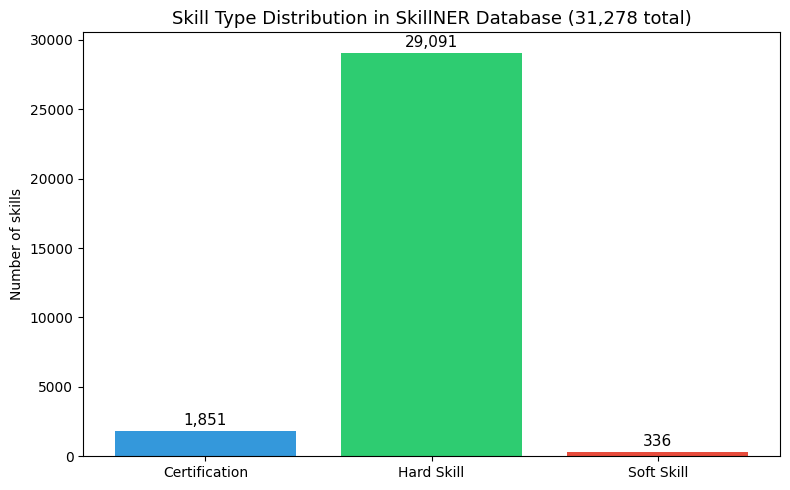

In [2]:
# Analyze skill type distribution in SKILL_DB
skill_types = {}
for skill_id, data in SKILL_DB.items():
    stype = data.get('skill_type', 'Unknown')
    skill_types[stype] = skill_types.get(stype, 0) + 1

print('Skill type distribution in SkillNER database:')
for stype, count in sorted(skill_types.items(), key=lambda x: -x[1]):
    print(f'  {stype}: {count:,} ({count/len(SKILL_DB)*100:.1f}%)')

# Bar chart
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#3498db', '#2ecc71', '#e74c3c']
bars = ax.bar(skill_types.keys(), skill_types.values(), color=colors[:len(skill_types)])
ax.set_title('Skill Type Distribution in SkillNER Database (31,278 total)', fontsize=13)
ax.set_ylabel('Number of skills')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 200,
            f'{height:,}', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.savefig(os.path.join('..', 'data', 'skilldb_distribution.png'), dpi=150)
plt.show()

## Skill Extraction on Real Job Descriptions

We run `extract_skills()` on 5 JDs from our dataset.
The function automatically detects **Must Have** and **Good to Have** sections
and classifies each skill accordingly.

In [3]:
# Load and process 5 Job Descriptions
jd_files = [
    'frontend_developer_01.txt',
    'machine_learning_engineer_01.txt',
    'data_analyst_01.txt',
    'devops_engineer_01.txt',
    'python_developer_01.txt'
]

all_results = {}

for filename in jd_files:
    filepath = os.path.join('..', 'data', 'job_descriptions', filename)

    if HAS_PARSER:
        text = parse_document(filepath)
    else:
        with open(filepath, 'r', encoding='utf-8') as f:
            text = f.read()

    skills = extract_skills(text, is_jd=True)
    all_results[filename] = skills

    job_title = filename.replace('_01.txt', '').replace('_', ' ').title()
    print(f'\n{"="*55}')
    print(f'JD: {job_title} — {len(skills)} skills extracted')
    print(f'{"="*55}')
    df = pd.DataFrame(skills)
    if not df.empty:
        print(df.to_string(index=False))


JD: Frontend Developer — 10 skills extracted
                              skill skill_type     priority
   HyperText Markup Language (HTML) Hard Skill    must_have
       Cascading Style Sheets (CSS) Hard Skill    must_have
  JavaScript (Programming Language) Hard Skill    must_have
                         TypeScript Hard Skill    must_have
                           React.js Hard Skill    must_have
                           Git Flow Hard Skill    must_have
                        RESTful API Hard Skill    must_have
                            Next.js Hard Skill good_to_have
Jest (JavaScript Testing Framework) Hard Skill good_to_have
            Figma (Design Software) Hard Skill good_to_have

JD: Machine Learning Engineer — 10 skills extracted
                                  skill skill_type     priority
                       Machine Learning Hard Skill    must_have
Scikit-learn (Machine Learning Library) Hard Skill    must_have
          Python (Programming Language) Hard Skil

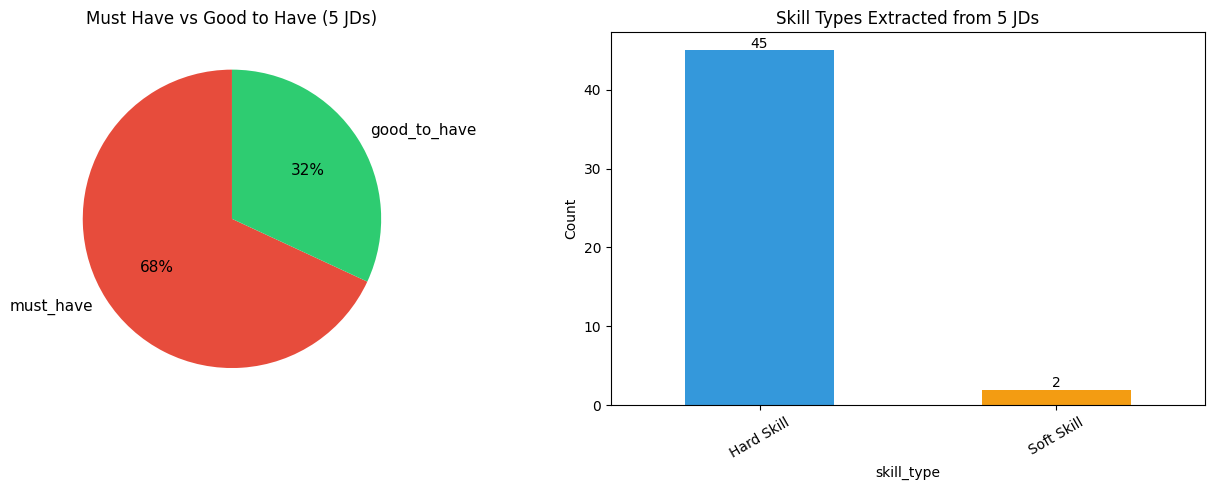

In [4]:
# Must Have vs Good to Have distribution across all 5 JDs
all_skills_flat = []
for filename, skills in all_results.items():
    job_title = filename.replace('_01.txt', '').replace('_', ' ').title()
    for s in skills:
        s_copy = s.copy()
        s_copy['jd'] = job_title
        all_skills_flat.append(s_copy)

all_df = pd.DataFrame(all_skills_flat)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pie chart: Must Have vs Good to Have
priority_counts = all_df['priority'].value_counts()
axes[0].pie(priority_counts.values, labels=priority_counts.index,
            autopct='%1.0f%%', colors=['#e74c3c', '#2ecc71'],
            startangle=90, textprops={'fontsize': 11})
axes[0].set_title('Must Have vs Good to Have (5 JDs)', fontsize=12)

# Bar chart: skill_type distribution
type_counts = all_df['skill_type'].value_counts()
colors = ['#3498db', '#f39c12', '#9b59b6']
type_counts.plot(kind='bar', ax=axes[1], color=colors[:len(type_counts)])
axes[1].set_title('Skill Types Extracted from 5 JDs', fontsize=12)
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=30)

for bar in axes[1].patches:
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
                 str(int(bar.get_height())), ha='center', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join('..', 'data', 'skill_extraction_charts.png'), dpi=150)
plt.show()

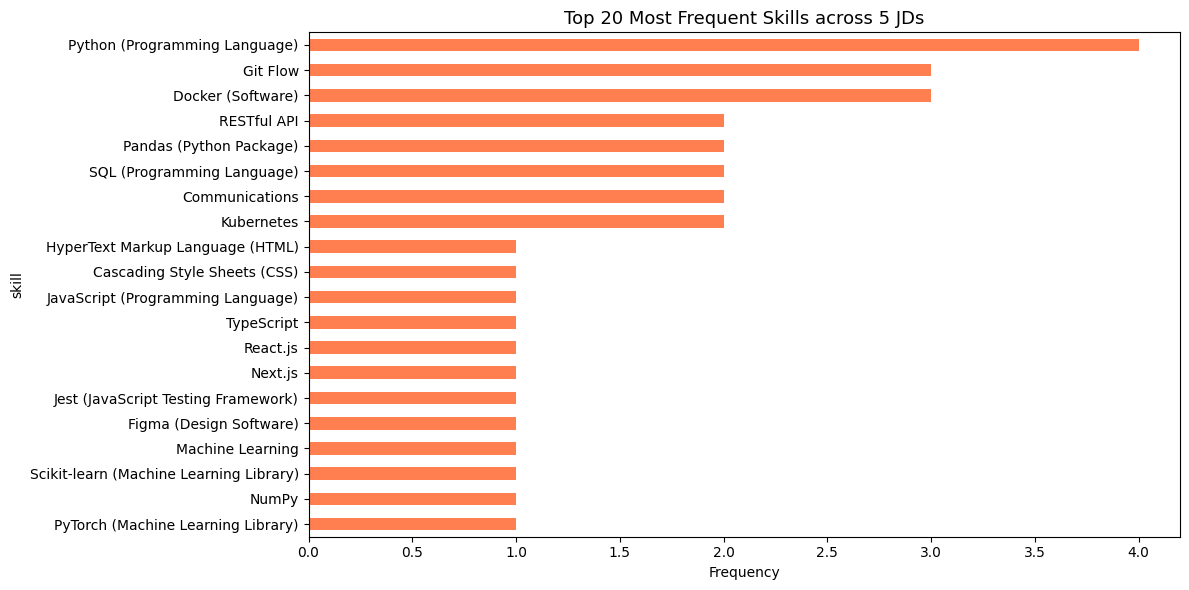

In [5]:
# Top 20 most frequent skills across all 5 JDs
top_skills = all_df['skill'].value_counts().head(20)

fig, ax = plt.subplots(figsize=(12, 6))
top_skills[::-1].plot(kind='barh', ax=ax, color='coral')
ax.set_title('Top 20 Most Frequent Skills across 5 JDs', fontsize=13)
ax.set_xlabel('Frequency')
plt.tight_layout()
plt.savefig(os.path.join('..', 'data', 'top20_skills.png'), dpi=150)
plt.show()

## Ground Truth Evaluation

We manually read 5 JDs and identified the real skills a human recruiter would notice.
We then compare this **ground truth** with what SkillNER extracted automatically.

Metrics used:
- **Precision** — of all skills extracted, how many are correct?
- **Recall** — of all real skills, how many did we find?
- **F1 Score** — harmonic mean of Precision and Recall

In [6]:
ground_truth = {
    'frontend_developer_01.txt': [
        'JavaScript', 'TypeScript', 'React', 'HTML', 'CSS',
        'Git', 'REST APIs', 'Next.js', 'Tailwind CSS', 'Jest', 'Figma'
    ],
    'machine_learning_engineer_01.txt': [
        'Python', 'Machine Learning', 'scikit-learn', 'Pandas', 'NumPy',
        'Natural Language Processing', 'Git', 'Docker',
        'PyTorch', 'TensorFlow', 'Hugging Face Transformers', 'FastAPI'
    ],
    'data_analyst_01.txt': [
        'SQL', 'Python', 'Pandas', 'Power BI', 'Data Visualization',
        'Tableau', 'BigQuery', 'Snowflake', 'Statistics'
    ],
    'devops_engineer_01.txt': [
        'Linux', 'Docker', 'Kubernetes', 'Terraform', 'AWS',
        'CI/CD', 'GitHub Actions', 'Git',
        'Helm', 'Prometheus', 'Grafana', 'Python'
    ],
    'python_developer_01.txt': [
        'Python', 'FastAPI', 'SQL', 'PostgreSQL', 'Git',
        'REST APIs', 'Docker', 'Unit Testing',
        'AWS', 'Kubernetes', 'CI/CD'
    ]
}


def skills_match(extracted_name: str, truth_name: str) -> bool:
    """Check if an extracted skill matches a ground truth skill.

    Handles cases where SkillNER returns full names like
    'HyperText Markup Language (HTML)' for ground truth 'HTML'.
    """
    e = extracted_name.lower().strip()
    t = truth_name.lower().strip()

    # Direct match
    if e == t:
        return True
    # One contains the other
    if t in e or e in t:
        return True
    # Check inside parentheses: 'hypertext markup language (html)' vs 'html'
    if '(' in e and ')' in e:
        inside_parens = e[e.find('(')+1:e.find(')')].strip()
        if inside_parens == t:
            return True
    return False


comparison_rows = []

for filename, true_skills in ground_truth.items():
    job_title = filename.replace('_01.txt', '').replace('_', ' ').title()

    extracted_names = [s['skill'] for s in all_results[filename]]

    true_positives = []
    false_negatives = []

    for t in true_skills:
        matched = any(skills_match(e, t) for e in extracted_names)
        if matched:
            true_positives.append(t)
        else:
            false_negatives.append(t)

    false_positives = []
    for e in extracted_names:
        matched = any(skills_match(e, t) for t in true_skills)
        if not matched:
            false_positives.append(e)

    precision = len(true_positives) / len(extracted_names) * 100 if extracted_names else 0
    recall = len(true_positives) / len(true_skills) * 100 if true_skills else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    comparison_rows.append({
        'JD': job_title,
        'Ground Truth': len(true_skills),
        'Extracted': len(extracted_names),
        'True Positives': len(true_positives),
        'Missed (FN)': len(false_negatives),
        'Extra (FP)': len(false_positives),
        'Precision %': round(precision, 1),
        'Recall %': round(recall, 1),
        'F1 %': round(f1, 1)
    })

    print(f'\n{job_title}')
    print(f'  Precision: {precision:.1f}% | Recall: {recall:.1f}% | F1: {f1:.1f}%')
    if false_negatives:
        print(f'  Missed: {false_negatives}')
    if false_positives:
        print(f'  Extra (FP): {false_positives[:5]}')

comp_df = pd.DataFrame(comparison_rows)
print(f'\n{"="*70}')
print('SUMMARY')
print(f'{"="*70}')
print(comp_df[['JD', 'Ground Truth', 'Extracted', 'True Positives',
               'Missed (FN)', 'Extra (FP)', 'Precision %', 'Recall %', 'F1 %']].to_string(index=False))
print(f'\nAverage Precision: {comp_df["Precision %"].mean():.1f}%')
print(f'Average Recall:    {comp_df["Recall %"].mean():.1f}%')
print(f'Average F1:        {comp_df["F1 %"].mean():.1f}%')


Frontend Developer
  Precision: 90.0% | Recall: 81.8% | F1: 85.7%
  Missed: ['REST APIs', 'Tailwind CSS']
  Extra (FP): ['RESTful API']

Machine Learning Engineer
  Precision: 90.0% | Recall: 75.0% | F1: 81.8%
  Missed: ['Natural Language Processing', 'Hugging Face Transformers', 'FastAPI']
  Extra (FP): ['Transformers (Electrical)']

Data Analyst
  Precision: 90.0% | Recall: 100.0% | F1: 94.7%
  Extra (FP): ['Communications']

Devops Engineer
  Precision: 112.5% | Recall: 75.0% | F1: 90.0%
  Missed: ['AWS', 'CI/CD', 'Helm']

Python Developer
  Precision: 77.8% | Recall: 63.6% | F1: 70.0%
  Missed: ['FastAPI', 'REST APIs', 'AWS', 'CI/CD']
  Extra (FP): ['RESTful API', 'Communications']

SUMMARY
                       JD  Ground Truth  Extracted  True Positives  Missed (FN)  Extra (FP)  Precision %  Recall %  F1 %
       Frontend Developer            11         10               9            2           1         90.0      81.8  85.7
Machine Learning Engineer            12         10   

## Conclusions

### What works well:
- **Rich skill names** — SkillNER returns full names like 'HyperText Markup Language (HTML)' and 'Jest (JavaScript Testing Framework)' instead of just 'HTML' or 'Jest'
- **Skill type classification** — automatically distinguishes Hard Skills, Soft Skills, and Certifications without any manual labeling
- **Context understanding** — finds skills expressed in different ways ('proficiency in Python', 'Python experience', 'Python developer')
- **Large vocabulary** — 31,278 skills vs the ~150 we had in the manual CSV

### Limitations:
- **False positives on noisy text** — PDFs with layout issues (columns, special fonts) produce garbled text that confuses SkillNER (e.g., 'M (Programming Language)' from 'MHP')
- **Skill name mismatch with ground truth** — SkillNER may return 'React.js' while the JD says 'React', making exact matching harder
- **Section detection is regex-based** — JDs without clear section headers get all skills classified as must_have
- **No typo tolerance** — misspelled skills are not detected

### Planned improvements for Week 14:
- Filter by skill_type (allow user to choose Hard Skills only, or include Soft Skills)
- Use `doc_node_score` confidence scores to rank extracted skills
- Full evaluation on all 15+ JDs with formal Precision/Recall/F1 report
- Error analysis: what types of skills does SkillNER miss and why?

In [3]:
# Save ground truth to CSV file
import pandas as pd
import os

ground_truth_export = {
    'frontend_developer_01.txt': {
        'must_have': ['JavaScript', 'TypeScript', 'React', 'HTML', 'CSS', 'Git', 'REST APIs'],
        'good_to_have': ['Next.js', 'Tailwind CSS', 'Jest', 'Figma']
    },
    'machine_learning_engineer_01.txt': {
        'must_have': ['Python', 'Machine Learning', 'scikit-learn', 'Pandas', 'NumPy', 'Natural Language Processing', 'Git', 'Docker'],
        'good_to_have': ['PyTorch', 'TensorFlow', 'Hugging Face Transformers', 'FastAPI']
    },
    'data_analyst_01.txt': {
        'must_have': ['SQL', 'Python', 'Pandas', 'Power BI', 'Data Visualization'],
        'good_to_have': ['Tableau', 'BigQuery', 'Snowflake', 'Statistics']
    },
    'devops_engineer_01.txt': {
        'must_have': ['Linux', 'Docker', 'Kubernetes', 'Terraform', 'AWS', 'CI/CD', 'GitHub Actions', 'Git'],
        'good_to_have': ['Helm', 'Prometheus', 'Grafana', 'Python']
    },
    'python_developer_01.txt': {
        'must_have': ['Python', 'FastAPI', 'SQL', 'PostgreSQL', 'Git', 'REST APIs', 'Docker', 'Unit Testing'],
        'good_to_have': ['AWS', 'Kubernetes', 'CI/CD']
    }
}

ground_truth_rows = []
for filename, priorities in ground_truth_export.items():
    for skill in priorities['must_have']:
        ground_truth_rows.append({'jd_file': filename, 'skill': skill, 'priority': 'must_have'})
    for skill in priorities['good_to_have']:
        ground_truth_rows.append({'jd_file': filename, 'skill': skill, 'priority': 'good_to_have'})

gt_df = pd.DataFrame(ground_truth_rows)
output_path = os.path.join('..', 'data', 'ground_truth', 'manual_labels.csv')
gt_df.to_csv(output_path, index=False)
print(f'Saved {len(gt_df)} rows to {output_path}')
print(gt_df.head(10).to_string(index=False))

Saved 55 rows to ..\data\ground_truth\manual_labels.csv
                  jd_file        skill     priority
frontend_developer_01.txt   JavaScript    must_have
frontend_developer_01.txt   TypeScript    must_have
frontend_developer_01.txt        React    must_have
frontend_developer_01.txt         HTML    must_have
frontend_developer_01.txt          CSS    must_have
frontend_developer_01.txt          Git    must_have
frontend_developer_01.txt    REST APIs    must_have
frontend_developer_01.txt      Next.js good_to_have
frontend_developer_01.txt Tailwind CSS good_to_have
frontend_developer_01.txt         Jest good_to_have
